In [1]:
import os, random, hashlib, time, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

DEBUG      = False    # True = tiny CPU dry run. Set False for the real run.
CHANNELS   = 1       # 1 = grayscale, 3 = RGB
IMG_SIZE   = 128
BATCH_SIZE = 64
EPOCHS     = 2 if DEBUG else 40
LR, WEIGHT_DECAY, PATIENCE, SEED = 2e-3, 1e-2, 8, 42
RUN_NAME   = f"cnn_{'gray' if CHANNELS == 1 else 'rgb'}{'_debug' if DEBUG else ''}"
OUT_DIR    = Path('/kaggle/working')

CLASSES = ["CatEye", "DogEye", "CatFace", "DogFace", "CatMouth", "DogMouth", "CatNose", "DogNose"]
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device, '| DEBUG:', DEBUG, '| CHANNELS:', CHANNELS)

Device: cuda | DEBUG: False | CHANNELS: 1


In [2]:
INPUT = Path('/kaggle/input')
EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
imgs = sorted(p for p in INPUT.rglob('*') if p.suffix.lower() in EXT)
csvs = sorted(INPUT.rglob('*.csv'))
print(len(imgs), 'images | CSVs:', [str(c) for c in csvs])

def norm(s): return str(s).strip().lower().rstrip('s')      # treats DogEye / DogEyes as the same
CANON = {norm(c): c for c in CLASSES}
def in_test(p): return any('test' in part.lower() for part in p.relative_to(INPUT).parts[1:-1])

test_paths = [p for p in imgs if in_test(p)]
train_imgs = [p for p in imgs if not in_test(p)]
sample_sub = next((c for c in csvs if 'sample' in c.name.lower() or 'submission' in c.name.lower()), None)
label_csv  = next((c for c in csvs if c != sample_sub and 'test' not in c.name.lower()), None)

if all(norm(p.parent.name) in CANON for p in train_imgs[:50]):
    print('Layout: class subfolders')
    train_df = pd.DataFrame({'path': train_imgs, 'label': [CANON[norm(p.parent.name)] for p in train_imgs]})
else:
    print('Layout: CSV labels ->', label_csv)
    lab = pd.read_csv(label_csv, dtype=str); print(lab.head(3))
    id_col  = 'image_id' if 'image_id' in lab.columns else lab.columns[0]
    cls_col = 'class' if 'class' in lab.columns else lab.columns[-1]
    s2p = {p.stem: p for p in train_imgs}
    lab['path'] = lab[id_col].map(lambda i: s2p.get(Path(str(i)).stem))
    lab = lab.dropna(subset=['path'])
    train_df = pd.DataFrame({'path': lab['path'], 'label': lab[cls_col].map(lambda s: CANON[norm(s)])})
train_df = train_df.reset_index(drop=True)

# Order test images exactly like the sample submission, matching ids as NUMBERS
# (files are '00001.jpg' but the sample file uses '1'); keep the sample file's id format for the output.
test_ids = [p.stem for p in test_paths]
if sample_sub is not None:
    ss = pd.read_csv(sample_sub, dtype=str)
    t2p = {int(p.stem): p for p in test_paths}
    test_ids   = [i for i in ss.iloc[:, 0] if int(i) in t2p]
    test_paths = [t2p[int(i)] for i in test_ids]
    print('Rows in sample submission:', len(ss), '| matched to test images:', len(test_ids))
    assert len(test_ids) == len(ss), 'Some sample-submission ids have no matching test image!'
    print('Sample submission class values seen:', ss.iloc[:, 1].unique()[:10])
print(f'Train {len(train_df)} | Test {len(test_paths)} | matched to sample sub: {sample_sub is not None}')
print(train_df['label'].value_counts())

93103 images | CSVs: ['/kaggle/input/datasets/iylabl/facial-feature-classification-challenge/sample_submission.csv', '/kaggle/input/datasets/iylabl/facial-feature-classification-challenge/train_labels.csv']
Layout: CSV labels -> /kaggle/input/datasets/iylabl/facial-feature-classification-challenge/train_labels.csv
  image_id     class
0    00001    DogEye
1    00002  DogMouth
2    00003   DogFace
Rows in sample submission: 29443 | matched to test images: 29443
Sample submission class values seen: ['DogEye' 'CatNose' 'DogFace' 'DogMouth' 'CatMouth' 'CatFace' 'DogNose'
 'CatEye']
Train 63660 | Test 29443 | matched to sample sub: True
label
CatEye      13884
DogEye      11580
CatNose      6942
CatFace      6942
CatMouth     6942
DogNose      5790
DogMouth     5790
DogFace      5790
Name: count, dtype: int64


Train images:   0%|          | 0/63660 [00:00<?, ?it/s]

Corrupted train images removed: 0


Test images:   0%|          | 0/29443 [00:00<?, ?it/s]

Unreadable test images (blank placeholder used): 0
Shapes: (63660, 128, 128, 3) (29443, 128, 128, 3)
Original sizes (min/mean/max): [[4.0, 4.0], [113.09520892240025, 109.73785736726359], [2219.0, 2219.0]]
Exact-duplicate images: 30 | duplicate groups with conflicting labels: 0


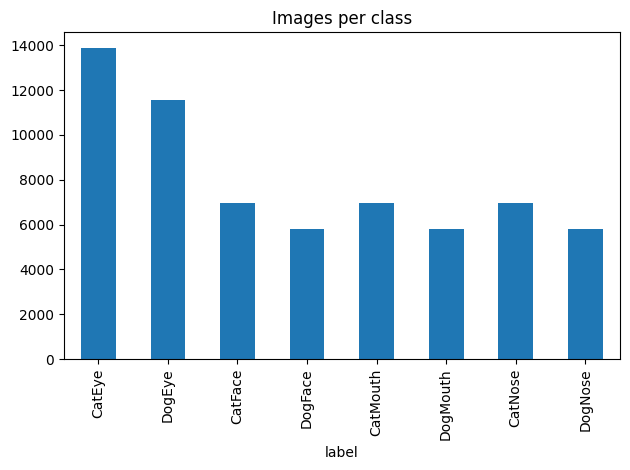

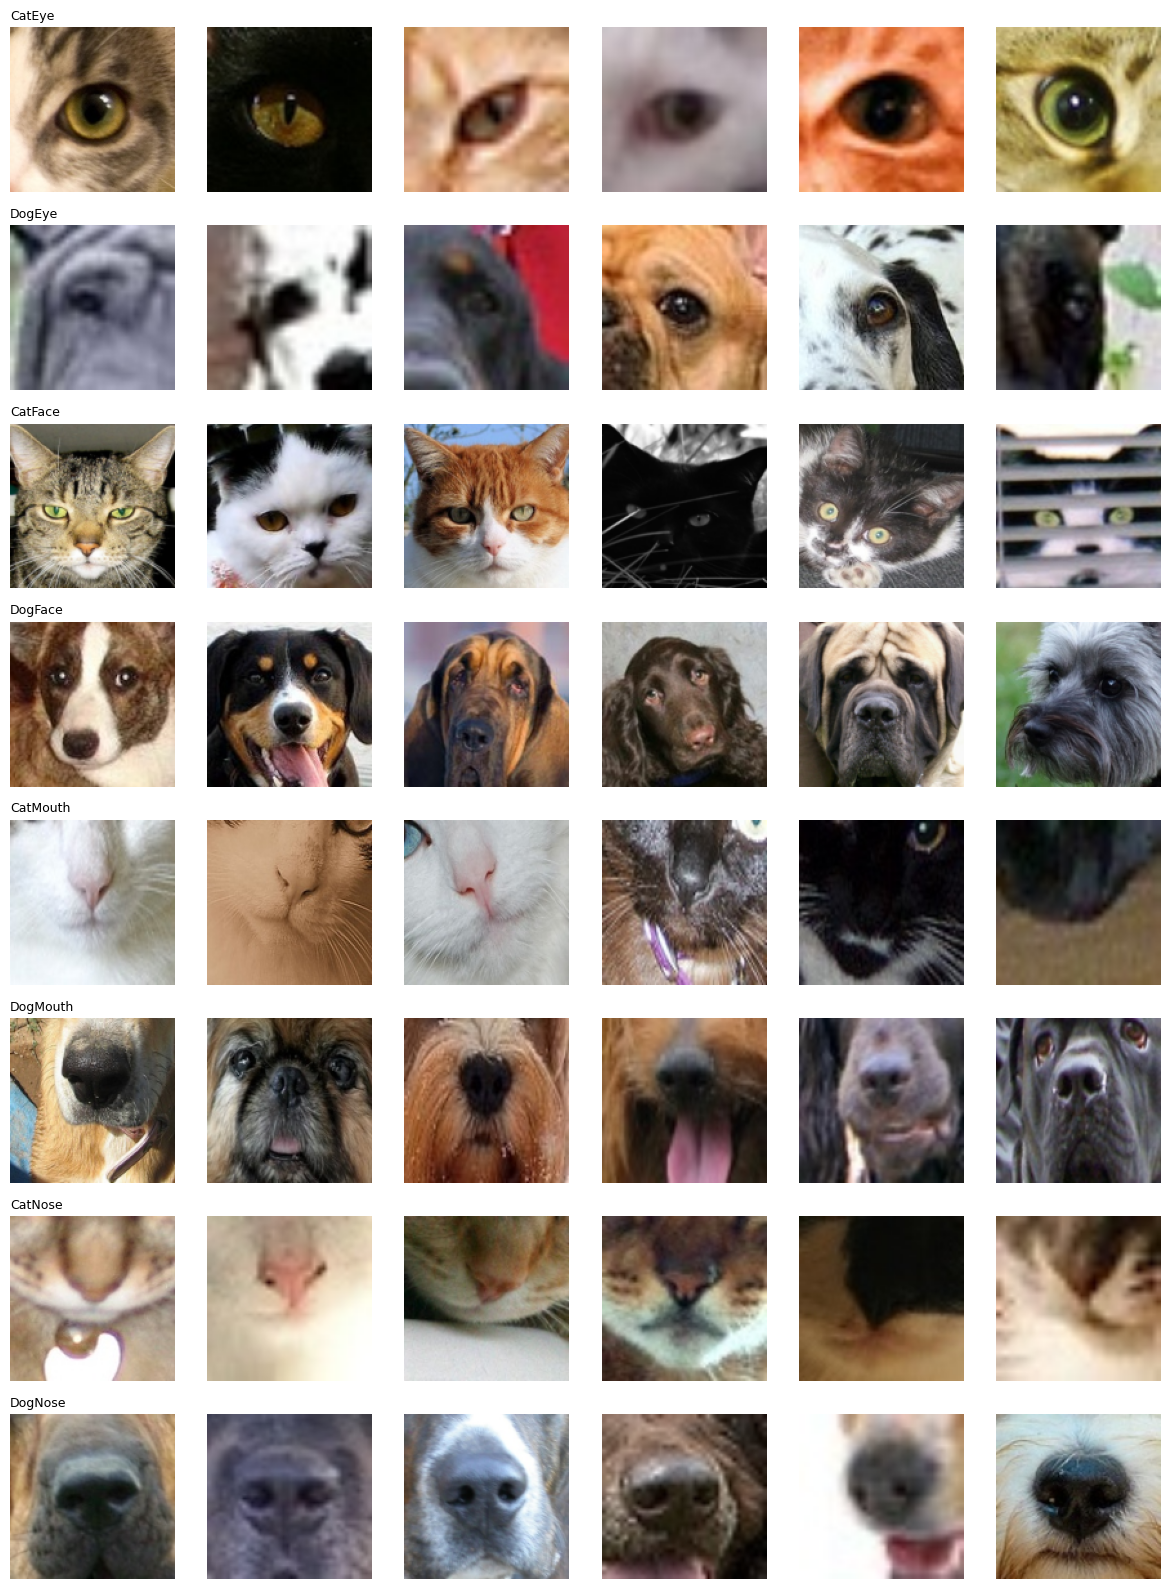

In [3]:
from multiprocessing import Pool
from tqdm.auto import tqdm

if DEBUG:
    train_df = train_df.groupby('label').head(50).reset_index(drop=True)
    test_paths, test_ids = test_paths[:100], test_ids[:100]

def load(p):
    try:
        raw = Path(p).read_bytes()
        im = Image.open(p); im.load()
        arr = np.asarray(im.convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))
        return arr, im.size[0], im.size[1], hashlib.md5(raw).hexdigest(), True
    except Exception:
        return None, 0, 0, '', False

CACHE = OUT_DIR / f"cache_{'debug' if DEBUG else 'full'}"
npz, pkl = CACHE.with_suffix('.npz'), CACHE.with_suffix('.pkl')
cache_ok = False
if npz.exists() and pkl.exists():
    z = np.load(npz)
    if 'test_ids' in z.files and list(z['test_ids']) == list(test_ids):
        X_all, X_test = z['X_all'], z['X_test']
        train_df = pd.read_pickle(pkl); cache_ok = True; print('Loaded cache')
    else:
        print('Cache is stale (test ids differ) - rebuilding')

if not cache_ok:
    with Pool(4) as pool:
        res = list(tqdm(pool.imap(load, train_df['path'].tolist(), chunksize=64),
                        total=len(train_df), desc='Train images'))
    train_df['w']   = [r[1] for r in res]
    train_df['h']   = [r[2] for r in res]
    train_df['md5'] = [r[3] for r in res]
    ok = np.array([r[4] for r in res], dtype=bool)
    X_all = np.stack([r[0] for r in res if r[4]])
    train_df = train_df[ok].reset_index(drop=True)
    print('Corrupted train images removed:', (~ok).sum())
    del res

    blank = np.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    with Pool(4) as pool:
        tres = list(tqdm(pool.imap(load, test_paths, chunksize=64),
                         total=len(test_paths), desc='Test images'))
    print('Unreadable test images (blank placeholder used):', sum(not r[4] for r in tres))
    X_test = np.stack([r[0] if r[4] else blank for r in tres])
    del tres

    np.savez(npz, X_all=X_all, X_test=X_test, test_ids=np.array(test_ids))
    train_df.to_pickle(pkl)

train_df['y'] = train_df['label'].map({c: i for i, c in enumerate(CLASSES)})
y_all = train_df['y'].values
print('Shapes:', X_all.shape, X_test.shape)
print('Original sizes (min/mean/max):', train_df[['w', 'h']].agg(['min', 'mean', 'max']).values.tolist())
dup = train_df.duplicated('md5', keep=False)
print('Exact-duplicate images:', dup.sum(),
      '| duplicate groups with conflicting labels:', (train_df[dup].groupby('md5')['label'].nunique() > 1).sum())

train_df['label'].value_counts().reindex(CLASSES).plot.bar(title='Images per class'); plt.tight_layout()
plt.savefig(OUT_DIR / 'class_counts.png', dpi=150); plt.show()

fig, axes = plt.subplots(len(CLASSES), 6, figsize=(12, 2 * len(CLASSES)))
for r, c in enumerate(CLASSES):
    idx = train_df.index[train_df['label'] == c][:6]
    for k, i in enumerate(idx): axes[r, k].imshow(X_all[i]); axes[r, k].axis('off')
    axes[r, 0].set_title(c, loc='left', fontsize=9)
plt.tight_layout(); plt.savefig(OUT_DIR / 'samples.png', dpi=120); plt.show()

Shorter side < 16px: 190 (0.3%)
Shorter side < 32px: 4130 (6.5%)
Shorter side < 64px: 23698 (37.2%)
Aspect ratio w/h (1%,5%,50%,95%,99%): [0.67, 0.81, 1.0, 1.42, 1.44]
           min    25%    50%    75%     max
label                                      
CatEye     4.0   44.0   68.0  100.0   340.0
CatFace   22.0  116.0  178.0  263.0   945.0
CatMouth   4.0   52.0   80.0  120.0   394.0
CatNose    4.0   44.0   68.0  100.0   340.0
DogEye    14.0   42.0   62.0   88.0   886.0
DogFace   39.0  109.0  155.0  224.0  2219.0
DogMouth  17.0   52.0   77.0  110.0  1107.0
DogNose   14.0   42.0   62.0   88.0   886.0


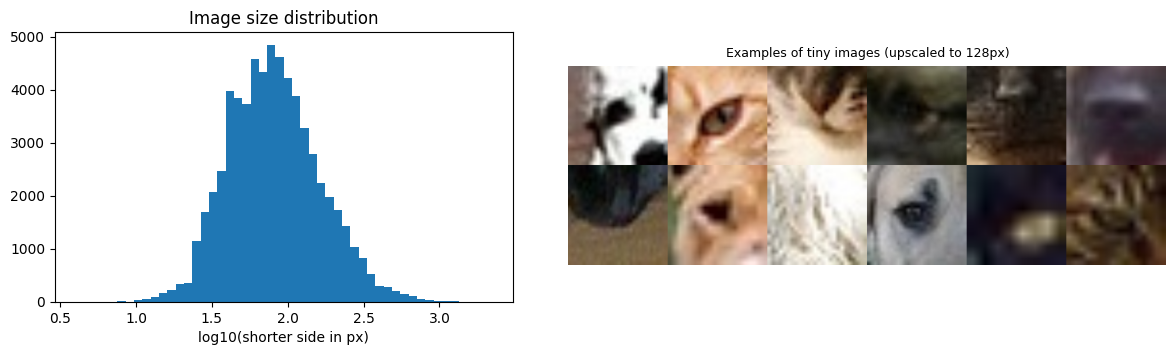

In [4]:
sz = train_df[['w', 'h', 'label']].copy()
sz['min_side'] = sz[['w', 'h']].min(axis=1)
sz['aspect'] = sz['w'] / sz['h'].clip(lower=1)
for t in (16, 32, 64):
    print(f'Shorter side < {t}px: {(sz.min_side < t).sum()} ({(sz.min_side < t).mean():.1%})')
print('Aspect ratio w/h (1%,5%,50%,95%,99%):', sz['aspect'].quantile([.01, .05, .5, .95, .99]).round(2).tolist())
print(sz.groupby('label')['min_side'].describe()[['min', '25%', '50%', '75%', 'max']].round(0))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].hist(np.log10(sz.min_side.clip(lower=1)), bins=50); ax[0].set_xlabel('log10(shorter side in px)'); ax[0].set_title('Image size distribution')
tiny = train_df.index[sz.min_side < 32][:12]
ax[1].axis('off')
inset = fig.add_axes([0.52, 0.05, 0.46, 0.9]); inset.axis('off')
inset.imshow(np.concatenate([np.concatenate([X_all[i] for i in tiny[r*6:(r+1)*6]], axis=1)
                             for r in range(2) if len(tiny[r*6:(r+1)*6]) == 6], axis=0))
inset.set_title('Examples of tiny images (upscaled to 128px)', fontsize=9)
plt.savefig(OUT_DIR / 'size_analysis.png', dpi=130, bbox_inches='tight'); plt.show()

In [5]:
lab = pd.read_csv(label_csv, dtype=str)
lab['num'] = lab.iloc[:, 0].astype(int)
lab = lab.sort_values('num')
cls = lab.iloc[:, 1].map(lambda s: CANON[norm(s)]).tolist()
print('First 20 labels by id:', cls[:20])

part = lambda c: c[3:]          # Eye, Face, Mouth, Nose
species = lambda c: c[:3]       # Cat / Dog
blocks = [cls[i:i + 5] for i in range(0, len(cls) - 4, 5)]
ok_parts = sum(sorted(map(part, b)) == ['Eye', 'Eye', 'Face', 'Mouth', 'Nose'] for b in blocks)
ok_species = sum(len({species(c) for c in b}) == 1 for b in blocks)
print(f'{ok_parts}/{len(blocks)} blocks of 5 consecutive ids = exactly Eye,Eye,Face,Mouth,Nose')
print(f'{ok_species}/{len(blocks)} blocks of 5 are a single species')

First 20 labels by id: ['DogEye', 'DogMouth', 'DogFace', 'DogNose', 'DogNose', 'DogEye', 'DogMouth', 'CatNose', 'CatFace', 'CatNose', 'CatFace', 'DogMouth', 'CatMouth', 'CatFace', 'CatEye', 'DogFace', 'CatEye', 'CatMouth', 'DogEye', 'DogEye']
1010/12732 blocks of 5 consecutive ids = exactly Eye,Eye,Face,Mouth,Nose
890/12732 blocks of 5 are a single species


In [6]:
print(os.cpu_count())

4


In [7]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
tr_idx, va_idx = next(sgkf.split(X_all, y_all, groups=train_df['md5']))  # duplicates never straddle the split
print(f'Train {len(tr_idx)} | Val {len(va_idx)}')

to_mode = T.Grayscale(1) if CHANNELS == 1 else T.Lambda(lambda im: im)
MEAN, STD = [0.5] * CHANNELS, [0.5] * CHANNELS
train_tf = T.Compose([to_mode, T.RandomHorizontalFlip(),
                      T.RandomAffine(12, translate=(0.08, 0.08), scale=(0.9, 1.1)),
                      T.ColorJitter(brightness=0.25, contrast=0.25), T.ToTensor(), T.Normalize(MEAN, STD)])
eval_tf  = T.Compose([to_mode, T.ToTensor(), T.Normalize(MEAN, STD)])

class DS(Dataset):
    def __init__(self, X, y, tf): self.X, self.y, self.tf = X, y, tf
    def __len__(self): return len(self.X)
    def __getitem__(self, i):
        img = self.tf(Image.fromarray(self.X[i]))
        return (img, int(self.y[i])) if self.y is not None else img

nw = 4
train_dl = DataLoader(DS(X_all[tr_idx], y_all[tr_idx], train_tf), BATCH_SIZE, shuffle=True, num_workers=nw)
val_dl   = DataLoader(DS(X_all[va_idx], y_all[va_idx], eval_tf), BATCH_SIZE, num_workers=nw)

def block(cin, cout, p):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        nn.MaxPool2d(2), nn.Dropout2d(p))

class CustomCNN(nn.Module):
    def __init__(self, in_ch=1, n_classes=8):
        super().__init__()
        self.features = nn.Sequential(block(in_ch, 32, 0.05), block(32, 64, 0.10),
                                      block(64, 128, 0.15), block(128, 256, 0.20))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.4), nn.Linear(256, n_classes))  # raw logits
    def forward(self, x): return self.head(self.pool(self.features(x)))

model = CustomCNN(CHANNELS, len(CLASSES)).to(device)
print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LR, epochs=EPOCHS, steps_per_epoch=len(train_dl))

Train 50930 | Val 12730
Parameters: 1,174,696


In [8]:
idx = tr_idx[:32]
xb = torch.stack([eval_tf(Image.fromarray(X_all[i])) for i in idx]).to(device)
yb = torch.tensor(y_all[idx]).to(device)
m = CustomCNN(CHANNELS, len(CLASSES)).to(device)
opt = torch.optim.AdamW(m.parameters(), lr=2e-3)
lossf = nn.CrossEntropyLoss()
for step in range(1, 61):
    m.train(); opt.zero_grad(); loss = lossf(m(xb), yb); loss.backward(); opt.step()
    if step % 10 == 0:
        m.eval()
        with torch.no_grad(): acc = (m(xb).argmax(1) == yb).float().mean().item()
        print(f'step {step:02d} | loss {loss.item():.3f} | accuracy on these 32 images {acc:.2f}')

step 10 | loss 1.115 | accuracy on these 32 images 0.34
step 20 | loss 0.867 | accuracy on these 32 images 0.25
step 30 | loss 0.830 | accuracy on these 32 images 0.41
step 40 | loss 0.618 | accuracy on these 32 images 0.53
step 50 | loss 0.490 | accuracy on these 32 images 0.69
step 60 | loss 0.353 | accuracy on these 32 images 0.72


In [9]:
t0 = time.time(); n = 0
for i, (x, y) in enumerate(train_dl):
    n += len(y)
    if i == 19: break
rate = n / (time.time() - t0)
print(f'{rate:.0f} images/s from the data loader -> about {len(tr_idx)/rate/60:.1f} min per epoch minimum')

1281 images/s from the data loader -> about 0.7 min per epoch minimum


In [10]:
use_amp = device.type == 'cuda'
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

def run_epoch(dl, train):
    model.train(train)
    loss_sum = correct = n = 0
    with torch.set_grad_enabled(train):
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out = model(x); loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update(); scheduler.step()
            loss_sum += loss.item() * len(y); correct += (out.argmax(1) == y).sum().item(); n += len(y)
    return loss_sum / n, correct / n

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val, bad, ckpt = float('inf'), 0, OUT_DIR / f'{RUN_NAME}_best.pt'
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tl, ta = run_epoch(train_dl, True); vl, va = run_epoch(val_dl, False)
    for k, v in zip(history, (tl, vl, ta, va)): history[k].append(v)
    print(f'Epoch {epoch:02d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.0f}s')
    if vl < best_val:
        best_val, bad = vl, 0; torch.save(model.state_dict(), ckpt)
    else:
        bad += 1
        if bad >= PATIENCE: print('Early stopping.'); break
json.dump(history, open(OUT_DIR / f'{RUN_NAME}_history.json', 'w'))

Epoch 01 | train loss 1.801 acc 0.339 | val loss 1.407 acc 0.552 | 50s
Epoch 02 | train loss 1.309 acc 0.616 | val loss 0.951 acc 0.823 | 53s
Epoch 03 | train loss 1.026 acc 0.771 | val loss 0.814 acc 0.877 | 54s
Epoch 04 | train loss 0.894 acc 0.840 | val loss 0.746 acc 0.912 | 53s
Epoch 05 | train loss 0.816 acc 0.883 | val loss 0.677 acc 0.952 | 53s
Epoch 06 | train loss 0.766 acc 0.906 | val loss 0.736 acc 0.922 | 53s
Epoch 07 | train loss 0.731 acc 0.921 | val loss 0.696 acc 0.938 | 53s
Epoch 08 | train loss 0.702 acc 0.935 | val loss 0.632 acc 0.968 | 53s
Epoch 09 | train loss 0.679 acc 0.944 | val loss 0.613 acc 0.971 | 53s
Epoch 10 | train loss 0.662 acc 0.950 | val loss 0.613 acc 0.967 | 53s
Epoch 11 | train loss 0.645 acc 0.957 | val loss 0.596 acc 0.978 | 53s
Epoch 12 | train loss 0.635 acc 0.959 | val loss 0.587 acc 0.977 | 53s
Epoch 13 | train loss 0.623 acc 0.963 | val loss 0.566 acc 0.978 | 53s
Epoch 14 | train loss 0.614 acc 0.967 | val loss 0.581 acc 0.976 | 53s
Epoch 

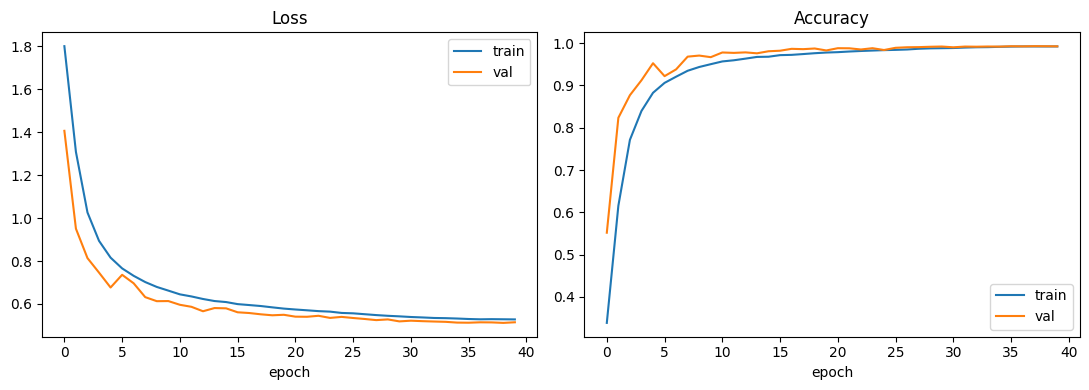

              precision    recall  f1-score   support

      CatEye      0.996     0.991     0.993      2758
      DogEye      0.982     0.994     0.988      2361
     CatFace      1.000     0.998     0.999      1348
     DogFace      0.997     0.997     0.997      1165
    CatMouth      0.993     0.989     0.991      1424
    DogMouth      0.999     0.995     0.997      1144
     CatNose      0.985     0.986     0.986      1373
     DogNose      0.996     0.993     0.994      1157

    accuracy                          0.993     12730
   macro avg      0.993     0.993     0.993     12730
weighted avg      0.993     0.993     0.993     12730



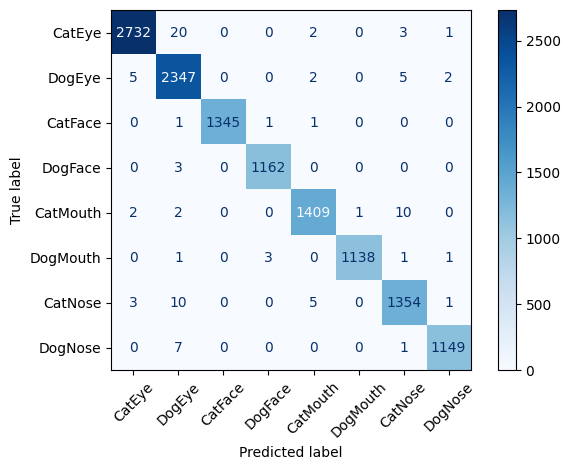

Validation accuracy: 0.9926158680282796


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history['train_loss'], label='train'); ax[0].plot(history['val_loss'], label='val'); ax[0].set_title('Loss')
ax[1].plot(history['train_acc'], label='train');  ax[1].plot(history['val_acc'], label='val');  ax[1].set_title('Accuracy')
for a in ax: a.set_xlabel('epoch'); a.legend()
plt.tight_layout(); plt.savefig(OUT_DIR / f'{RUN_NAME}_curves.png', dpi=150); plt.show()

model.load_state_dict(torch.load(ckpt, map_location=device)); model.eval()
preds, trues = [], []
with torch.no_grad():
    for x, y in val_dl:
        preds += model(x.to(device)).argmax(1).cpu().tolist(); trues += y.tolist()
print(classification_report(trues, preds, labels=range(len(CLASSES)), target_names=CLASSES, digits=3, zero_division=0))
cm = confusion_matrix(trues, preds, labels=range(len(CLASSES)))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(xticks_rotation=45, cmap='Blues')
plt.tight_layout(); plt.savefig(OUT_DIR / f'{RUN_NAME}_confusion.png', dpi=150); plt.show()
print('Validation accuracy:', np.mean(np.array(preds) == np.array(trues)))

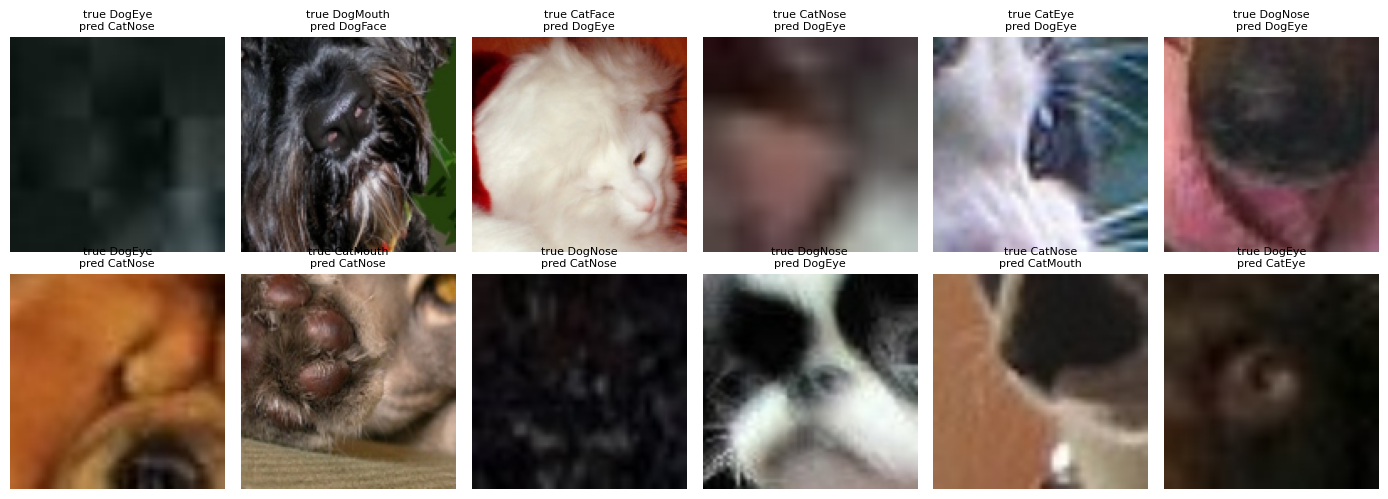

In [12]:
wrong = [i for i, (p, t) in enumerate(zip(preds, trues)) if p != t][:12]
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for a in axes.ravel(): a.axis('off')
for a, i in zip(axes.ravel(), wrong):
    a.imshow(X_all[va_idx[i]])
    a.set_title(f'true {CLASSES[trues[i]]}\npred {CLASSES[preds[i]]}', fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / f'{RUN_NAME}_errors.png', dpi=120); plt.show()

In [13]:
test_dl = DataLoader(DS(X_test, None, eval_tf), BATCH_SIZE, num_workers=nw)
probs = []
with torch.no_grad():
    for x in test_dl:
        x = x.to(device)
        probs.append((model(x).softmax(1) + model(torch.flip(x, dims=[3])).softmax(1)).cpu())  # flip TTA
test_pred = torch.cat(probs).argmax(1).numpy()

# Use the exact class spelling found in train_labels.csv (e.g. DogEye vs DogEyes)
raw = pd.read_csv(label_csv, dtype=str)
ccol = 'class' if 'class' in raw.columns else raw.columns[-1]
spelling = {CANON[norm(s)]: s for s in raw[ccol].unique()}
print('Spelling used in train_labels.csv:', spelling)

sub = pd.DataFrame({'image_id': test_ids, 'class': [spelling[CLASSES[i]] for i in test_pred]})
sub_path = OUT_DIR / ('submission_debug.csv' if DEBUG else 'submission.csv')
sub.to_csv(sub_path, index=False)
print(sub.head(), '\nRows:', len(sub), '| saved to', sub_path)
if sample_sub is not None:
    print('Sample submission head:\n', pd.read_csv(sample_sub, dtype=str).head(3))

Spelling used in train_labels.csv: {'DogEye': 'DogEye', 'DogMouth': 'DogMouth', 'DogFace': 'DogFace', 'DogNose': 'DogNose', 'CatNose': 'CatNose', 'CatFace': 'CatFace', 'CatMouth': 'CatMouth', 'CatEye': 'CatEye'}
  image_id     class
0        1    DogEye
1        2  DogMouth
2        3   DogNose
3        4   DogFace
4        5  CatMouth 
Rows: 29443 | saved to /kaggle/working/submission.csv
Sample submission head:
   image_id    class
0        1   DogEye
1        2  CatNose
2        3  CatNose


In [14]:
import os
from IPython.display import FileLink, display
os.chdir('/kaggle/working')
!ls -lh /kaggle/working
for f in ['submission.csv', 'cnn_gray_best.pt', 'cnn_gray_history.json',
          'cnn_gray_curves.png', 'cnn_gray_confusion.png', 'cnn_gray_errors.png']:
    if os.path.exists(f): display(FileLink(f))
    else: print('MISSING:', f)

total 4.3G
-rw-r--r-- 1 root root 4.3G Oct 23 00:13 cache_full.npz
-rw-r--r-- 1 root root 9.5M Oct 23 00:13 cache_full.pkl
-rw-r--r-- 1 root root  39K Oct 23 00:13 class_counts.png
-rw-r--r-- 1 root root 4.6M Oct 23 00:48 cnn_gray_best.pt
-rw-r--r-- 1 root root  77K Oct 23 00:49 cnn_gray_confusion.png
-rw-r--r-- 1 root root  62K Oct 23 00:49 cnn_gray_curves.png
-rw-r--r-- 1 root root 712K Oct 23 00:49 cnn_gray_errors.png
-rw-r--r-- 1 root root 3.2K Oct 23 00:49 cnn_gray_history.json
-rw-r--r-- 1 root root 3.6M Oct 23 00:50 __notebook__.ipynb
-rw-r--r-- 1 root root 2.4M Oct 23 00:13 samples.png
-rw-r--r-- 1 root root 234K Oct 23 00:13 size_analysis.png
-rw-r--r-- 1 root root 386K Oct 23 00:50 submission.csv


/kaggle/working/submission.csv

/kaggle/working/cnn_gray_best.pt

/kaggle/working/cnn_gray_history.json

/kaggle/working/cnn_gray_curves.png

/kaggle/working/cnn_gray_confusion.png

/kaggle/working/cnn_gray_errors.png